In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import io, json, os, random, hashlib, re, time, gc, subprocess
from collections import Counter
from itertools import combinations
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import matplotlib.pyplot as plt
import requests
from PIL import Image, ImageOps
from tqdm import tqdm

# the numbers of the guide
KB_SIZE, VALIDATION_SIZE = 10000, 100
TEST_PER_SCENE = {'simple': 34, 'medium': 33, 'complex': 33}
TEST_SIZE = sum(TEST_PER_SCENE.values())
TEST_PER_SCENE_1000 = {'simple': 334, 'medium': 333, 'complex': 333}
TEST_1000_SIZE = sum(TEST_PER_SCENE_1000.values())
SEED = 42

# object detector
DETECTOR = 'facebook/detr-resnet-50'
DETECTOR_MIN_SCORE = 0.5
ANNOTATION_CONFIDENCE = 1.0

# folders (everything is saved in Drive)
BASE = '/content/drive/MyDrive/RAG-Phase1'
FOLDER = {'train_kb': 'images/train', 'validation': 'images/validation',
          'test': 'images/test', 'test_1000': 'images/test'}
for folder in [*FOLDER.values(), 'plots', 'embeddings', 'index', 'metadata']:
    os.makedirs(f'{BASE}/{folder}', exist_ok=True)

ANN = '/content/annotations'      # COCO annotation files (they live in /content, so they are lost when Colab restarts)


def get_annotations():
    """Download the COCO annotations only when they are needed (about 1 minute)."""
    if os.path.exists(f'{ANN}/instances_train2017.json'):
        return
    url = 'http://images.cocodataset.org/annotations/annotations_trainval2017.zip'
    subprocess.run(['wget', '-nc', '-q', url, '-P', '/content'], check=True)
    subprocess.run(['unzip', '-n', '-q', '/content/annotations_trainval2017.zip', '-d', '/content'], check=True)


def load_json(path):
    with open(path) as f:
        return json.load(f)


def save_json(data, path):
    with open(path, 'w') as f:
        json.dump(data, f)


def clean_text(text):
    """For retrieval only: lowercase + no punctuation. The original caption is never changed."""
    return re.sub(r'[^a-z0-9 ]', '', text.lower()).strip()


def scene_type(number_of_objects):
    """simple = 0-2 objects, medium = 3-5, complex = 6 or more."""
    if number_of_objects <= 2:
        return 'simple'
    if number_of_objects <= 5:
        return 'medium'
    return 'complex'


def load_splits():
    """Load what Part 1 saved: the lists of image ids + the 5 captions of each image."""
    splits = load_json(f'{BASE}/splits.json')
    captions = {int(k): v for k, v in load_json(f'{BASE}/captions.json').items()}
    return splits, captions


def require(*names):
    """Stop with a clear message if a variable is missing (this happens after a Colab restart)."""
    missing = [n for n in names if n not in globals()]
    if missing:
        raise RuntimeError(f'Missing: {missing}. Colab was restarted or a cell was skipped. '
                           'Run Setup, then the FIRST cell of this Part, then continue in order.')


# ----- plot helpers (used by Part 2 and Part 3) -----
def show(title, xlabel, ylabel, filename):
    """Add the labels, save the plot in Drive and display it."""
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.savefig(f'{BASE}/plots/{filename}', bbox_inches='tight')
    plt.show()
    plt.close()


def bar_plot(counts, title, ylabel, filename):
    labels = [label for label, n in counts.most_common()]
    plt.figure(figsize=(8, 4))
    plt.bar(labels, [counts[label] for label in labels])
    plt.xticks(rotation=45, ha='right')
    show(title, '', ylabel, filename)


def hist_plot(values, title, xlabel, ylabel, filename, bins=30):
    plt.figure(figsize=(7, 4))
    plt.hist(values, bins=bins, edgecolor='black')
    show(title, xlabel, ylabel, filename)


def top_classes_plot(counts, title, filename, n=50):
    top = counts.most_common(n)[::-1]
    plt.figure(figsize=(8, 12))
    plt.barh([name for name, c in top], [c for name, c in top])
    show(title, 'Number of objects', '', filename)


print('Setup done. Part 1 already finished on Drive:', os.path.exists(f'{BASE}/splits.json'))

Mounted at /content/drive
Setup done. Part 1 already finished on Drive: True


## Part 1: Data audit, cleaning and splits

In [ ]:
# 1.1) Functions of Part 1 (nothing runs here, it only defines them)
def group_captions(data):
    """{image id: [its captions]} and {image id: download link}."""
    captions = {}
    for a in data['annotations']:
        captions.setdefault(a['image_id'], []).append(a['caption'].strip())
    urls = {img['id']: img['coco_url'] for img in data['images']}
    return captions, urls


def download(ids, urls, folder, workers=16):
    """Download many images at the same time. Images that are already on disk are skipped."""
    def fetch(i):
        path = f'{folder}/{i:012d}.jpg'
        if os.path.exists(path):
            return
        for attempt in range(3):
            try:
                response = requests.get(urls[i], timeout=30)
                if response.status_code == 200:
                    with open(path + '.part', 'wb') as f:          # write to a temporary name first,
                        f.write(response.content)
                    os.replace(path + '.part', path)               # so an interrupted download never leaves a half image
                    return
            except (requests.RequestException, OSError):
                time.sleep(1)

    with ThreadPoolExecutor(workers) as pool:
        list(tqdm(pool.map(fetch, ids), total=len(ids)))


def inspect_image(path):
    """Returns ('missing' | 'corrupted' | 'ok', fingerprint). The file is read only once."""
    if not os.path.exists(path):
        return 'missing', None
    with open(path, 'rb') as f:
        data = f.read()
    try:
        Image.open(io.BytesIO(data)).verify()
    except Exception:
        return 'corrupted', None
    return 'ok', hashlib.md5(data).hexdigest()           # same file = same fingerprint


def build_clean_set(ids, urls, spare, folder, already_used=()):
    """Download + audit one set. Removes missing, corrupted and duplicate images (keeps the first copy)
    and replaces them with spares so the set stays full.
    Gives back: ids of the good images, their fingerprints, and how many images were removed.
    already_used = fingerprints of the earlier sets: the same picture can never be in two sets."""
    target = len(ids)
    kept, fingerprints, seen = [], set(), set(already_used)
    removed = {'missing': 0, 'corrupted': 0, 'duplicate': 0}
    todo = list(ids)
    while todo:
        download(todo, urls, folder)
        paths = [f'{folder}/{i:012d}.jpg' for i in todo]
        with ThreadPoolExecutor(16) as pool:
            results = list(pool.map(inspect_image, paths))
        for i, path, (status, fingerprint) in zip(todo, paths, results):
            if status == 'missing':
                removed['missing'] += 1
            elif status == 'corrupted':
                os.remove(path)
                removed['corrupted'] += 1
            elif fingerprint in seen:                          # duplicate (in this set or in an earlier set)
                os.remove(path)
                removed['duplicate'] += 1
            else:
                seen.add(fingerprint)
                fingerprints.add(fingerprint)
                kept.append(i)
        need = target - len(kept)
        if need > len(spare):
            raise RuntimeError('Not enough spare images left. Is the internet connection working?')
        todo = [spare.pop() for _ in range(need)]              # replacements (empty list = finished)
    print(folder.split('/')[-1], '-> kept', len(kept), '| removed', removed)
    return kept, fingerprints, removed

In [ ]:
# 1.2) Run Part 1 (KB 10,000 + validation 100 from train2017, test 100 from val2017)
def build_part1():
    get_annotations()

    # 1) Captions of every image
    train_captions, train_urls = group_captions(load_json(f'{ANN}/captions_train2017.json'))
    val_captions, val_urls = group_captions(load_json(f'{ANN}/captions_val2017.json'))

    # 2) KB + validation: random train2017 images with exactly 5 captions. The others are "spares".
    #    KB and validation come from ONE shuffled list, so they can never share an image.
    rng = random.Random(SEED)
    train_ok = sorted(i for i, c in train_captions.items() if len(c) == 5)
    rng.shuffle(train_ok)
    kb_ids = train_ok[:KB_SIZE]
    validation_ids = train_ok[KB_SIZE:KB_SIZE + VALIDATION_SIZE]
    train_spare = train_ok[KB_SIZE + VALIDATION_SIZE:]

    # 3) Test: val2017 images, stratified by scene complexity (= number of objects). Spares are kept per scene type,
    #    so a replacement never breaks the 34 / 33 / 33 balance.
    val_instances = load_json(f'{ANN}/instances_val2017.json')
    objects_in_image = Counter(a['image_id'] for a in val_instances['annotations'])
    del val_instances
    scenes = {'simple': [], 'medium': [], 'complex': []}
    for i in sorted(val_captions):
        if len(val_captions[i]) == 5 and objects_in_image[i] > 0:
            scenes[scene_type(objects_in_image[i])].append(i)
    test_picked, test_spare = {}, {}
    for scene, how_many in TEST_PER_SCENE.items():
        rng.shuffle(scenes[scene])
        test_picked[scene] = scenes[scene][:how_many]
        test_spare[scene] = scenes[scene][how_many:]
    print('Picked:', len(kb_ids), 'KB |', len(validation_ids), 'validation |', sum(map(len, test_picked.values())), 'test')

    # 4) Download + audit
    kb_ids, kb_fp, kb_removed = build_clean_set(kb_ids, train_urls, train_spare, f'{BASE}/{FOLDER["train_kb"]}')
    validation_ids, val_fp, val_removed = build_clean_set(validation_ids, train_urls, train_spare,
                                                          f'{BASE}/{FOLDER["validation"]}', kb_fp)
    test_ids, test_fp = [], set()
    test_removed = {'missing': 0, 'corrupted': 0, 'duplicate': 0}
    for scene in TEST_PER_SCENE:
        kept, fp, removed = build_clean_set(test_picked[scene], val_urls, test_spare[scene],
                                            f'{BASE}/{FOLDER["test"]}', kb_fp | val_fp | test_fp)
        test_ids += kept
        test_fp |= fp
        test_removed = {k: test_removed[k] + removed[k] for k in test_removed}

    # 5) Checks + leakage audit (the code stops with an error if something is wrong)
    sets = {'train_kb': kb_ids, 'validation': validation_ids, 'test': test_ids}
    fingerprints = {'train_kb': kb_fp, 'validation': val_fp, 'test': test_fp}
    expected = {'train_kb': KB_SIZE, 'validation': VALIDATION_SIZE, 'test': TEST_SIZE}
    captions = {}
    for name, ids in sets.items():
        folder = f'{BASE}/{FOLDER[name]}'
        wanted = {f'{i:012d}.jpg' for i in ids}
        for f in os.listdir(folder):                           # remove leftovers of earlier runs
            if f not in wanted and f.endswith(('.jpg', '.part')):
                os.remove(f'{folder}/{f}')
        source = val_captions if name == 'test' else train_captions
        for i in ids:
            captions[i] = source[i]
        assert len(ids) == expected[name] and len(set(ids)) == len(ids), f'{name}: wrong number of ids'
        jpgs = [f for f in os.listdir(folder) if f.endswith('.jpg')]
        assert len(jpgs) == len(ids), f'{name}: image files and ids do not match'
    assert all(len(c) == 5 and all(t.strip() for t in c) for c in captions.values()), 'an image has not 5 good captions'

    audit = {}
    for a, b in combinations(sets, 2):                         # no image may be in two sets
        shared_ids = set(sets[a]) & set(sets[b])
        shared_pictures = fingerprints[a] & fingerprints[b]
        audit[f'{a}_vs_{b}'] = {'shared_ids': len(shared_ids), 'shared_pictures': len(shared_pictures)}
        assert not shared_ids and not shared_pictures, f'LEAKAGE between {a} and {b}'
    print('All checks passed. Leakage audit:', audit)

    # 6) Save: frozen split ids, raw captions, audit, cleaning report, fingerprints
    save_json(captions, f'{BASE}/captions.json')
    save_json(audit, f'{BASE}/metadata/leakage_audit.json')
    save_json({'train_kb': kb_removed, 'validation': val_removed, 'test': test_removed},
              f'{BASE}/metadata/cleaning_report.json')
    save_json({name: sorted(fp) for name, fp in fingerprints.items()}, f'{BASE}/metadata/fingerprints.json')
    save_json(sets, f'{BASE}/splits.json')                     # saved LAST: if it exists, Part 1 really finished


if os.path.exists(f'{BASE}/splits.json'):
    print('Part 1 is already done (splits.json exists on Drive). Nothing to download.')
    print('To redo it from zero, delete splits.json from the RAG-Phase1 folder in Drive.\n')
    splits, _ = load_splits()
    for name, ids in splits.items():
        on_disk = len([f for f in os.listdir(f'{BASE}/{FOLDER[name]}') if f.endswith('.jpg')])
        print(f'{name:<11}: {len(ids)} ids | {on_disk} images in the folder')
else:
    build_part1()

Part 1 is already done (splits.json exists on Drive). Nothing to download.
To redo it from zero, delete splits.json from the RAG-Phase1 folder in Drive.

train_kb   : 10000 ids | 10000 images in the folder
validation : 100 ids | 100 images in the folder
test       : 100 ids | 100 images in the folder


In [ ]:
# 1.3) NEW: extend the test set from 100 to 1,000 images (val2017).
#      The first 100 images stay INSIDE the 1,000, so both test sets can be compared (test_100 is a subset of test_1000).
def ensure_audit_files(splits):
    """Load fingerprints.json, leakage_audit.json and cleaning_report.json. If one is missing (older run of Part 1),
    rebuild it by re-auditing the images that are on Drive (about 2-4 minutes for 10,200 images)."""
    paths = {k: f'{BASE}/metadata/{k}.json' for k in ['fingerprints', 'leakage_audit', 'cleaning_report']}
    fingerprints = load_json(paths['fingerprints']) if os.path.exists(paths['fingerprints']) else None
    audit = load_json(paths['leakage_audit']) if os.path.exists(paths['leakage_audit']) else None
    report = load_json(paths['cleaning_report']) if os.path.exists(paths['cleaning_report']) else None
    if fingerprints is None:
        print('fingerprints.json not found: rebuilding it from the images on Drive ...')
        fingerprints, scanned = {}, {}
        for name in ['train_kb', 'validation', 'test']:
            folder = f'{BASE}/{FOLDER[name]}'
            with ThreadPoolExecutor(16) as pool:
                results = list(tqdm(pool.map(inspect_image, [f'{folder}/{i:012d}.jpg' for i in splits[name]]), total=len(splits[name]), desc=name))
            status = Counter(s for s, f in results)
            good = [f for s, f in results if s == 'ok']
            fingerprints[name] = sorted(set(good))
            scanned[name] = {'missing': status['missing'], 'corrupted': status['corrupted'], 'duplicate': len(good) - len(set(good))}
        save_json(fingerprints, paths['fingerprints'])
        if report is None:
            report = scanned                                          # re-audit of the final sets (the original removal counts are not recoverable)
            save_json(report, paths['cleaning_report'])
    if audit is None:
        audit = {}
        for a, b in combinations(['train_kb', 'validation', 'test'], 2):
            shared_pictures = set(fingerprints[a]) & set(fingerprints[b])
            audit[f'{a}_vs_{b}'] = {'shared_ids': len(set(splits[a]) & set(splits[b])), 'shared_pictures': len(shared_pictures)}
            assert not audit[f'{a}_vs_{b}']['shared_ids'] and not shared_pictures, f'LEAKAGE between {a} and {b}'
        save_json(audit, paths['leakage_audit'])
    return fingerprints, audit, report or {}


def extend_test_set():
    splits, captions = load_splits()
    if 'test_1000' in splits:
        print('test_1000 already exists:', len(splits['test_1000']), 'images. Nothing to do.')
        return
    get_annotations()
    val_captions, val_urls = group_captions(load_json(f'{ANN}/captions_val2017.json'))
    val_instances = load_json(f'{ANN}/instances_val2017.json')
    objects_in_image = Counter(a['image_id'] for a in val_instances['annotations'])
    del val_instances

    test_100 = splits['test']
    old = set(test_100)
    have = Counter(scene_type(objects_in_image[i]) for i in test_100)        # 34 / 33 / 33
    pool = {'simple': [], 'medium': [], 'complex': []}
    for i in sorted(val_captions):                                           # candidates: not already used, 5 captions, >= 1 object
        if i not in old and len(val_captions[i]) == 5 and objects_in_image[i] > 0:
            pool[scene_type(objects_in_image[i])].append(i)

    rng = random.Random(SEED + 1)                                            # another fixed seed (the 100 images do not move)
    fingerprints, audit, report = ensure_audit_files(splits)
    used = set().union(*[set(fp) for fp in fingerprints.values()])           # KB + validation + the first 100 test images
    folder = f'{BASE}/{FOLDER["test_1000"]}'
    new_ids, new_fp = [], set()
    removed_total = {'missing': 0, 'corrupted': 0, 'duplicate': 0}
    for scene, wanted in TEST_PER_SCENE_1000.items():
        need = wanted - have[scene]                                          # 300 more of each scene type
        rng.shuffle(pool[scene])
        kept, fp, removed = build_clean_set(pool[scene][:need], val_urls, pool[scene][need:], folder, used | new_fp)
        new_ids += kept
        new_fp |= fp
        removed_total = {k: removed_total[k] + removed[k] for k in removed_total}

    # checks (the code stops with an error if something is wrong)
    test_1000 = test_100 + new_ids
    assert len(test_1000) == TEST_1000_SIZE and len(set(test_1000)) == TEST_1000_SIZE, 'wrong number of test ids'
    assert not set(test_1000) & (set(splits['train_kb']) | set(splits['validation'])), 'LEAKAGE by id'
    wanted_files = {f'{i:012d}.jpg' for i in test_1000}
    for f in os.listdir(folder):                                             # remove leftovers of earlier runs
        if f not in wanted_files and f.endswith(('.jpg', '.part')):
            os.remove(f'{folder}/{f}')
    assert len([f for f in os.listdir(folder) if f.endswith('.jpg')]) == TEST_1000_SIZE, 'image files and ids do not match'
    for i in new_ids:
        captions[i] = val_captions[i]
    assert all(len(captions[i]) == 5 and all(t.strip() for t in captions[i]) for i in test_1000), 'an image has not 5 good captions'

    test_fp = set(fingerprints['test']) | new_fp
    for other in ['train_kb', 'validation']:
        shared = set(fingerprints[other]) & test_fp
        audit[f'{other}_vs_test_1000'] = {'shared_ids': len(set(splits[other]) & set(test_1000)), 'shared_pictures': len(shared)}
        assert not shared, f'LEAKAGE between {other} and test_1000'
    audit['test_100_is_inside_test_1000'] = set(test_100) <= set(test_1000)

    print('Scene types of the 1,000 test images:', dict(Counter(scene_type(objects_in_image[i]) for i in test_1000)))
    print('Removed while building the 900 new images:', removed_total)
    print('Leakage audit:', audit)

    report['test_1000_new_900'] = removed_total
    fingerprints['test_1000'] = sorted(test_fp)
    save_json(captions, f'{BASE}/captions.json')
    save_json(audit, f'{BASE}/metadata/leakage_audit.json')
    save_json(report, f'{BASE}/metadata/cleaning_report.json')
    save_json(fingerprints, f'{BASE}/metadata/fingerprints.json')
    splits['test_1000'] = test_1000
    save_json(splits, f'{BASE}/splits.json')                                 # saved LAST


extend_test_set()
splits, _ = load_splits()
print({name: len(ids) for name, ids in splits.items()})

fingerprints.json not found: rebuilding it from the images on Drive ...


100%|██████████| 300/300 [00:08<00:00, 35.43it/s]


test -> kept 300 | removed {'missing': 0, 'corrupted': 0, 'duplicate': 0}


100%|██████████| 300/300 [00:08<00:00, 35.46it/s]


test -> kept 300 | removed {'missing': 0, 'corrupted': 0, 'duplicate': 0}


100%|██████████| 300/300 [00:08<00:00, 35.42it/s]


test -> kept 300 | removed {'missing': 0, 'corrupted': 0, 'duplicate': 0}
Scene types of the 1,000 test images: {'simple': 334, 'medium': 333, 'complex': 333}
Removed while building the 900 new images: {'missing': 0, 'corrupted': 0, 'duplicate': 0}
Leakage audit: {'train_kb_vs_validation': {'shared_ids': 0, 'shared_pictures': 0}, 'train_kb_vs_test': {'shared_ids': 0, 'shared_pictures': 0}, 'validation_vs_test': {'shared_ids': 0, 'shared_pictures': 0}, 'train_kb_vs_test_1000': {'shared_ids': 0, 'shared_pictures': 0}, 'validation_vs_test_1000': {'shared_ids': 0, 'shared_pictures': 0}, 'test_100_is_inside_test_1000': True}
{'train_kb': 10000, 'validation': 100, 'test': 100, 'test_1000': 1000}


## Part 2: Object extraction + statistical exploration (before / after preprocessing)

Order of the work: **2.1** load the data → **2.2** explore the RAW data (*before*) → **2.3** extract the objects from the images with a detector → **2.4** choose the confidence threshold → **2.5** attributes + POS → **2.6** explore the PREPARED data (*after*, based on the detected objects) → **2.7** save everything.

In [ ]:
# 2.1) CHANGED: load the splits and the human COCO annotations (used as reference, "before" and for evaluation)
splits, captions = load_splits()
kb_ids, validation_ids = splits['train_kb'], splits['validation']
test_ids, test1000_ids = splits['test'], splits['test_1000']

CACHE = f'{BASE}/metadata/objects_cache.json'


def read_objects(ids, annotation_file):
    """{image id: ['person', 'dog', ...]} for the given images, and {class: supercategory}."""
    data = load_json(annotation_file)
    name = {c['id']: c['name'] for c in data['categories']}
    group = {c['name']: c['supercategory'] for c in data['categories']}
    found = {i: [] for i in ids}
    for a in data['annotations']:
        if a['image_id'] in found:
            found[a['image_id']].append(name[a['category_id']])
    del data
    gc.collect()                                              # the annotation file is huge: free the memory
    return found, group


coco_objects, group_of = {}, {}
if os.path.exists(CACHE):
    cache = load_json(CACHE)
    group_of = cache['group_of']
    coco_objects = {int(k): v for k, v in cache['objects'].items()}
train_todo = [i for i in kb_ids + validation_ids if i not in coco_objects]
test_todo = [i for i in test1000_ids if i not in coco_objects]
if train_todo or test_todo:
    get_annotations()
    if train_todo:
        found, group_of = read_objects(train_todo, f'{ANN}/instances_train2017.json')
        coco_objects.update(found)
    if test_todo:
        found, group_of_val = read_objects(test_todo, f'{ANN}/instances_val2017.json')
        coco_objects.update(found)
        group_of = group_of or group_of_val
    save_json({'group_of': group_of, 'objects': coco_objects}, CACHE)

print({name: len(ids) for name, ids in splits.items()}, '| images with COCO annotations loaded:', len(coco_objects))

{'train_kb': 10000, 'validation': 100, 'test': 100, 'test_1000': 1000} | images with COCO annotations loaded: 11100


BEFORE preprocessing (KB, 10,000 images)
  Colour modes             : {'RGB': 9985, 'L': 15} -> every image will be converted to RGB
  Images with EXIF rotation: 0 -> orientation will be corrected
  Average image size       : 579 x 483
  Average caption length   : 10.45 words (raw captions)
  Vocabulary size (raw)    : 16255 (upper/lower case and punctuation count as different words)
  COCO objects per image   : 7.19 | images without objects: 90


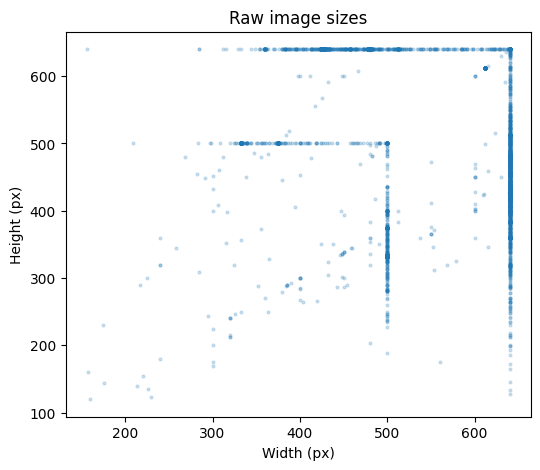

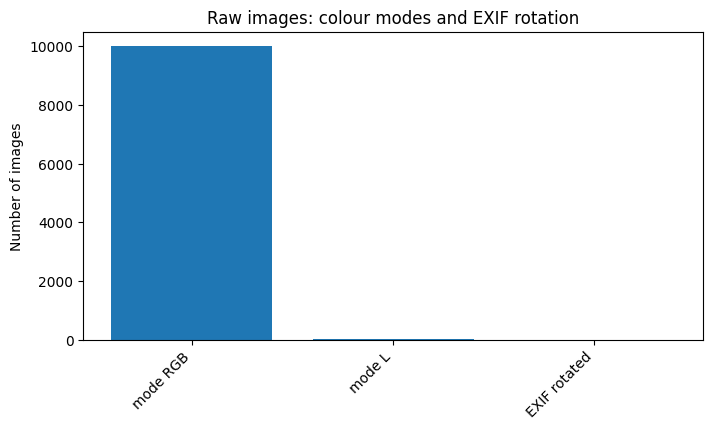

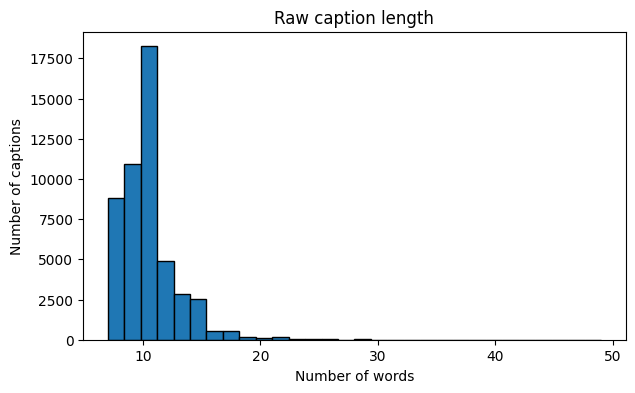

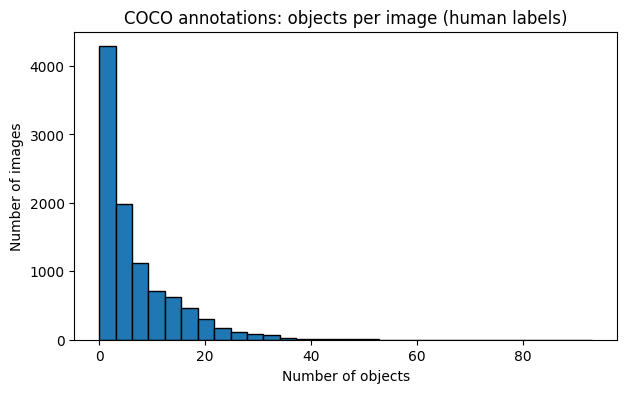

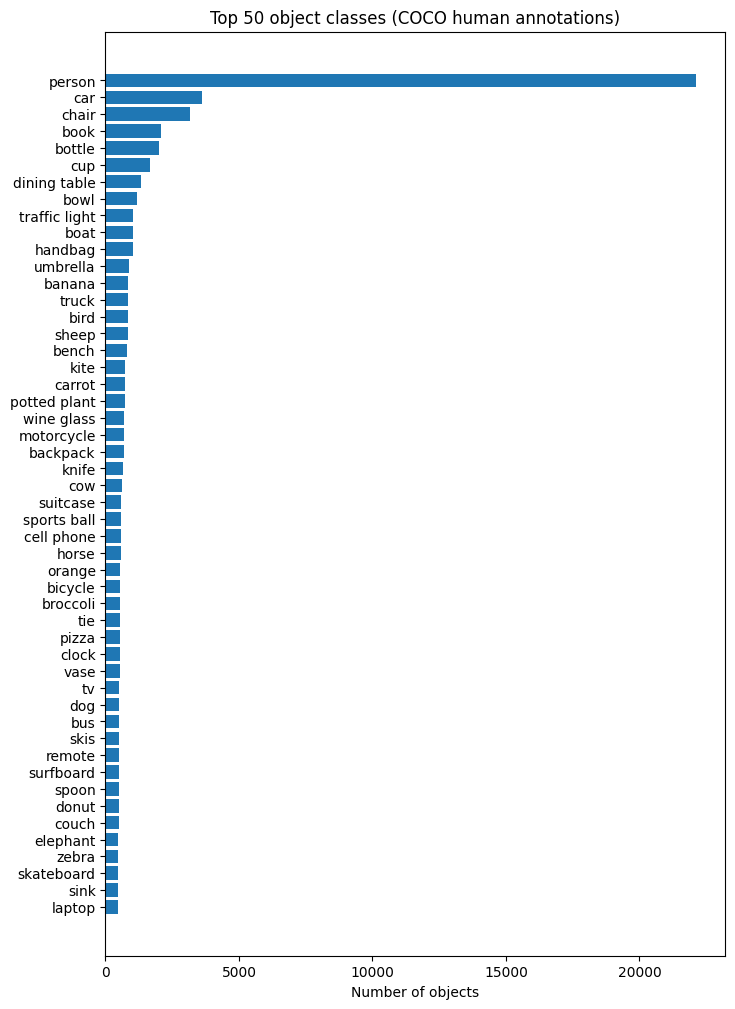

In [ ]:
# 2.2) NEW: exploration BEFORE preprocessing (raw images, raw captions, human COCO annotations)
require('kb_ids', 'captions', 'coco_objects')
PROPS = f'{BASE}/metadata/image_properties.json'


def read_properties(item):
    """Only the header of the image file is read (fast): size, colour mode, EXIF rotation tag."""
    name, i = item
    path = f'{BASE}/{FOLDER[name]}/{i:012d}.jpg'
    with Image.open(path) as im:
        return i, {'width': im.width, 'height': im.height, 'mode': im.mode,
                   'exif_orientation': int(im.getexif().get(0x0112, 1)), 'file_kb': round(os.path.getsize(path) / 1024, 1)}


if os.path.exists(PROPS):
    properties = {int(k): v for k, v in load_json(PROPS).items()}
else:
    items = [('train_kb', i) for i in kb_ids] + [('validation', i) for i in validation_ids] + [('test_1000', i) for i in test1000_ids]
    with ThreadPoolExecutor(16) as pool:
        properties = dict(tqdm(pool.map(read_properties, items), total=len(items)))
    save_json(properties, PROPS)

kb_props = [properties[i] for i in kb_ids]
modes = Counter(p['mode'] for p in kb_props)
rotated = sum(p['exif_orientation'] != 1 for p in kb_props)
raw_caption_lengths = [len(c.split()) for i in kb_ids for c in captions[i]]
raw_vocabulary = {w for i in kb_ids for c in captions[i] for w in c.split()}        # raw: upper/lower case and punctuation kept
coco_per_image = [len(coco_objects[i]) for i in kb_ids]
coco_class_counts = Counter(n for i in kb_ids for n in coco_objects[i])

before = {'images': len(kb_ids),
          'image_modes': dict(modes), 'images_with_exif_rotation': rotated,
          'average_width': float(np.mean([p['width'] for p in kb_props])), 'average_height': float(np.mean([p['height'] for p in kb_props])),
          'average_caption_length_raw': float(np.mean(raw_caption_lengths)), 'vocabulary_raw': len(raw_vocabulary),
          'coco_average_objects_per_image': float(np.mean(coco_per_image)), 'coco_images_without_objects': coco_per_image.count(0),
          'coco_top_50_classes': coco_class_counts.most_common(50)}
print('BEFORE preprocessing (KB, 10,000 images)')
print('  Colour modes             :', dict(modes), '-> every image will be converted to RGB')
print('  Images with EXIF rotation:', rotated, '-> orientation will be corrected')
print('  Average image size       :', round(before['average_width']), 'x', round(before['average_height']))
print('  Average caption length   :', round(before['average_caption_length_raw'], 2), 'words (raw captions)')
print('  Vocabulary size (raw)    :', len(raw_vocabulary), '(upper/lower case and punctuation count as different words)')
print('  COCO objects per image   :', round(before['coco_average_objects_per_image'], 2), '| images without objects:', before['coco_images_without_objects'])

plt.figure(figsize=(6, 5))
plt.scatter([p['width'] for p in kb_props], [p['height'] for p in kb_props], s=4, alpha=0.2)
show('Raw image sizes', 'Width (px)', 'Height (px)', 'before_image_sizes.png')
bar_plot(Counter({**{f'mode {m}': n for m, n in modes.items()}, 'EXIF rotated': rotated}),
         'Raw images: colour modes and EXIF rotation', 'Number of images', 'before_modes_exif.png')
hist_plot(raw_caption_lengths, 'Raw caption length', 'Number of words', 'Number of captions', 'before_caption_length.png')
hist_plot(coco_per_image, 'COCO annotations: objects per image (human labels)', 'Number of objects', 'Number of images', 'before_coco_objects_per_image.png')
top_classes_plot(coco_class_counts, 'Top 50 object classes (COCO human annotations)', 'before_coco_top_50_classes.png')

In [ ]:
# 2.3) NEW: extract the objects DIRECTLY FROM THE IMAGES with a detector (DETR). Needs a GPU (about 10 minutes for 11,000 images).
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import DetrForObjectDetection, DetrImageProcessor

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using:', device)
if device == 'cpu':
    print('WARNING: no GPU. This will take very long. Runtime > Change runtime type > T4 GPU (then run Setup again).')
DET_BATCH = 16
det_processor = DetrImageProcessor.from_pretrained(DETECTOR)
try:
    det_model = DetrForObjectDetection.from_pretrained(DETECTOR, revision='no_timm')     # version without the timm dependency
except Exception:
    subprocess.run(['pip', 'install', '-q', 'timm'], check=True)
    det_model = DetrForObjectDetection.from_pretrained(DETECTOR)
det_model = det_model.to(device).eval()
LABELS = det_model.config.id2label


class DetectionImages(Dataset):
    """Same preparation as for CLIP: EXIF rotation fixed + RGB."""
    def __init__(self, items):
        self.items = items                                     # (image id, path)

    def __len__(self):
        return len(self.items)

    def __getitem__(self, k):
        i, path = self.items[k]
        return i, ImageOps.exif_transpose(Image.open(path)).convert('RGB')


def det_collate(batch):
    ids = [i for i, _ in batch]
    images = [im for _, im in batch]
    return ids, det_processor(images=images, return_tensors='pt'), torch.tensor([im.size[::-1] for im in images])   # sizes = (height, width)


def detect_objects(ids, set_name):
    """{image id: [{'label', 'score', 'box'}]} for every detection with score >= DETECTOR_MIN_SCORE.
    Progress is saved every 1,000 images, so a Colab disconnection never loses everything."""
    cache_path = f'{BASE}/metadata/detections_{set_name}.json'
    done = {int(k): v for k, v in load_json(cache_path).items()} if os.path.exists(cache_path) else {}
    todo = [i for i in ids if i not in done]
    folder = f'{BASE}/{FOLDER[set_name]}'
    for start in range(0, len(todo), 1000):
        chunk = todo[start:start + 1000]
        loader = DataLoader(DetectionImages([(i, f'{folder}/{i:012d}.jpg') for i in chunk]),
                            batch_size=DET_BATCH, num_workers=2, collate_fn=det_collate)       # no shuffle: order kept
        for batch_ids, inputs, sizes in tqdm(loader, desc=f'{set_name} {start}/{len(todo)}'):
            with torch.no_grad():
                outputs = det_model(**inputs.to(device))
            results = det_processor.post_process_object_detection(outputs, threshold=DETECTOR_MIN_SCORE, target_sizes=sizes.to(device))
            for i, r in zip(batch_ids, results):
                done[i] = [{'label': LABELS[int(l)], 'score': round(float(s), 3), 'box': [round(float(v), 1) for v in b]}
                           for s, l, b in zip(r['scores'], r['labels'], r['boxes']) if LABELS[int(l)] != 'N/A']
        save_json(done, cache_path)
    return {i: done[i] for i in ids}


start_time = time.time()
detections = {'train_kb': detect_objects(kb_ids, 'train_kb'),
              'validation': detect_objects(validation_ids, 'validation'),
              'test_1000': detect_objects(test1000_ids, 'test_1000')}              # contains the 100 images of test_100
all_detections = {i: d for per_set in detections.values() for i, d in per_set.items()}
print('Detection finished for', len(all_detections), 'images in', round(time.time() - start_time), 'seconds (0 = everything was already cached)')
print('Example (image', kb_ids[0], '):', all_detections[kb_ids[0]][:3])

Using: cuda


Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

[transformers] DetrForObjectDetection LOAD REPORT from: facebook/detr-resnet-50
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
model.backbone.model.layer1.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
test_1000 0/1000: 100%|██████████| 63/63 [06:32<00:00,  6.23s/it]


Detection finished for 11100 images in 3199 seconds (0 = everything was already cached)
Example (image 228867 ): [{'label': 'person', 'score': 0.672, 'box': [114.3, 133.5, 136.5, 168.1]}, {'label': 'bed', 'score': 0.776, 'box': [203.6, 205.2, 488.5, 414.4]}, {'label': 'chair', 'score': 0.942, 'box': [549.2, 236.9, 578.2, 300.1]}]


threshold | precision | recall |   F1     (validation images)
   0.5    |   0.882   | 0.958  | 0.918
   0.6    |   0.897   | 0.955  | 0.925
   0.7    |   0.909   | 0.943  | 0.926
   0.8    |   0.939   | 0.932  | 0.935
   0.9    |   0.975   | 0.902  | 0.937
Chosen threshold for the detector: 0.9
Human annotations / captions (COCO) are not detected, they are written by people: confidence = 1.0


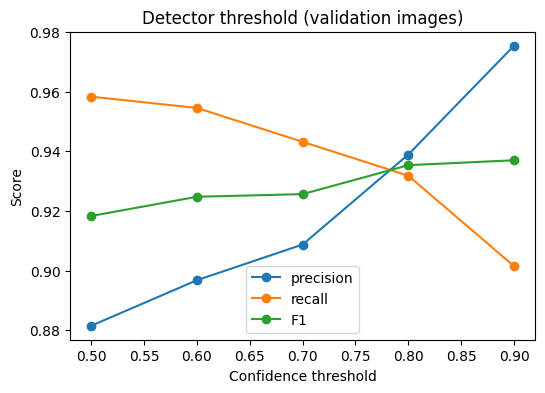

Detector vs human annotations on train_kb : precision 0.950 | recall 0.893 | F1 0.920
Detector vs human annotations on test_1000: precision 0.914 | recall 0.795 | F1 0.850
Detector vs human annotations on test_100 : precision 0.897 | recall 0.813 | F1 0.853


In [ ]:
# 2.4) NEW: confidence threshold of the detector, chosen on the VALIDATION images (never on the test images)
require('all_detections', 'coco_objects', 'validation_ids', 'kb_ids')


def labels_above(i, threshold):
    return [d['label'] for d in all_detections[i] if d['score'] >= threshold]


def agreement(ids, threshold):
    """Do the detected classes match the human COCO classes? (which classes are present in the image)"""
    tp = fp = fn = 0
    for i in ids:
        predicted, truth = set(labels_above(i, threshold)), set(coco_objects[i])
        tp += len(predicted & truth)
        fp += len(predicted - truth)
        fn += len(truth - predicted)
    precision, recall = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return precision, recall, 2 * precision * recall / max(precision + recall, 1e-9)


THRESHOLDS = [0.5, 0.6, 0.7, 0.8, 0.9]
sweep = {t: agreement(validation_ids, t) for t in THRESHOLDS}
print('threshold | precision | recall |   F1     (validation images)')
for t, (p, r, f) in sweep.items():
    print(f'   {t:.1f}    |   {p:.3f}   | {r:.3f}  | {f:.3f}')
DETECTION_THRESHOLD = max(sweep, key=lambda t: sweep[t][2])                      # best F1
print('Chosen threshold for the detector:', DETECTION_THRESHOLD)
print('Human annotations / captions (COCO) are not detected, they are written by people: confidence =', ANNOTATION_CONFIDENCE)

plt.figure(figsize=(6, 4))
for k, name in enumerate(['precision', 'recall', 'F1']):
    plt.plot(THRESHOLDS, [sweep[t][k] for t in THRESHOLDS], marker='o', label=name)
plt.legend()
show('Detector threshold (validation images)', 'Confidence threshold', 'Score', 'detector_threshold.png')

# the detector objects used as metadata
detected = {i: [d for d in all_detections[i] if d['score'] >= DETECTION_THRESHOLD] for i in all_detections}   # label + score + box
objects = {i: [d['label'] for d in detected[i]] for i in kb_ids}                                                # KB: labels only
quality = {'train_kb': agreement(kb_ids, DETECTION_THRESHOLD), 'test_1000': agreement(test1000_ids, DETECTION_THRESHOLD),
           'test_100': agreement(test_ids, DETECTION_THRESHOLD)}
for name, (p, r, f) in quality.items():
    print(f'Detector vs human annotations on {name:<9}: precision {p:.3f} | recall {r:.3f} | F1 {f:.3f}')
save_json({'detector': DETECTOR, 'min_score_stored': DETECTOR_MIN_SCORE, 'chosen_threshold': DETECTION_THRESHOLD,
           'selection': 'best F1 on the 100 validation images', 'sweep': {str(t): v for t, v in sweep.items()},
           'quality_vs_coco': quality, 'human_data_confidence': ANNOTATION_CONFIDENCE}, f'{BASE}/metadata/detector_config.json')

In [ ]:
# 2.5) Per-image attributes from the caption words + part-of-speech distribution
require('kb_ids', 'captions')
import nltk
for package in ['averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng']:
    nltk.download(package, quiet=True)

# COCO does not give colours, shapes, context or relations, so we take them from the words of the 5 HUMAN captions
# (human-written = confidence 1). These attributes exist for the KB images only: the captions of validation/test images are never used.
WORDS = {
    'colours': {c: [c] for c in ['white', 'black', 'red', 'blue', 'green', 'yellow', 'brown', 'orange', 'pink', 'purple', 'gray', 'grey']},
    'shapes_sizes': {s: [s] for s in ['round', 'square', 'rectangular', 'circular', 'long', 'tall', 'flat', 'small', 'big', 'large']},
    'context': {'indoor': ['kitchen', 'bathroom', 'bedroom', 'room', 'indoor', 'indoors', 'inside', 'office'],
                'outdoor': ['street', 'beach', 'field', 'park', 'road', 'outside', 'outdoor', 'grass', 'snow', 'city'],
                'day': ['sunny', 'daytime', 'day'],
                'night': ['night', 'dark', 'evening']},
    'spatial_relations': {'next to': ['next to', 'beside'], 'behind': ['behind'], 'under': ['under', 'beneath', 'below'],
                          'above': ['above', 'over'], 'in front of': ['in front of'], 'near': ['near', 'close to'],
                          'between': ['between'], 'on top of': ['on top of']},
}


def find_labels(text, word_groups):
    """Which labels appear in the text? (spaces around each word = whole words only)"""
    return [label for label, words in word_groups.items() if any(f' {w} ' in text for w in words)]


texts = {i: ' ' + ' '.join(clean_text(c) for c in captions[i]) + ' ' for i in kb_ids}
attributes = {i: {kind: find_labels(texts[i], groups) for kind, groups in WORDS.items()} for i in kb_ids}

diversity = {kind: Counter() for kind in WORDS}               # how many images have each label
for i in kb_ids:
    for kind, labels in attributes[i].items():
        diversity[kind].update(labels)


def coarse_pos(tag):
    """Group the detailed tags (NN, NNS, NNP ...) into readable classes."""
    if tag.startswith('NN'):
        return 'noun'
    if tag.startswith('VB'):
        return 'verb'
    if tag.startswith('JJ'):
        return 'adjective'
    if tag.startswith('RB'):
        return 'adverb'
    return {'IN': 'preposition', 'DT': 'determiner', 'CC': 'conjunction', 'CD': 'number',
            'PRP': 'pronoun', 'PRP$': 'pronoun'}.get(tag, 'other')


all_captions = [c for i in kb_ids for c in captions[i]]
pos_counts = Counter()
for c in random.Random(SEED).sample(all_captions, min(5000, len(all_captions))):
    for word, tag in nltk.pos_tag(clean_text(c).split()):
        pos_counts[coarse_pos(tag)] += 1

print('Context :', dict(diversity['context']))
print('POS     :', dict(pos_counts.most_common()))
print('Example :', kb_ids[0], attributes[kb_ids[0]])

Context : {'indoor': 1663, 'day': 404, 'outdoor': 3737, 'night': 267}
POS     : {'noun': 18550, 'determiner': 10740, 'preposition': 8430, 'verb': 6108, 'adjective': 4145, 'other': 1323, 'conjunction': 1202, 'pronoun': 712, 'number': 676, 'adverb': 314}
Example : 228867 {'colours': [], 'shapes_sizes': [], 'context': ['indoor'], 'spatial_relations': []}


                                    BEFORE         AFTER
Objects per image                     7.19          6.15   (human COCO labels -> detector)
Images without objects                  90           100
Avg caption length (words)           10.45         10.45
Vocabulary size                      16255         10080   (raw -> lowercase, no punctuation)
Scene types (detector)      : {'complex': 3916, 'simple': 3213, 'medium': 2871}
Different object categories : 80 | average detection confidence: 0.975


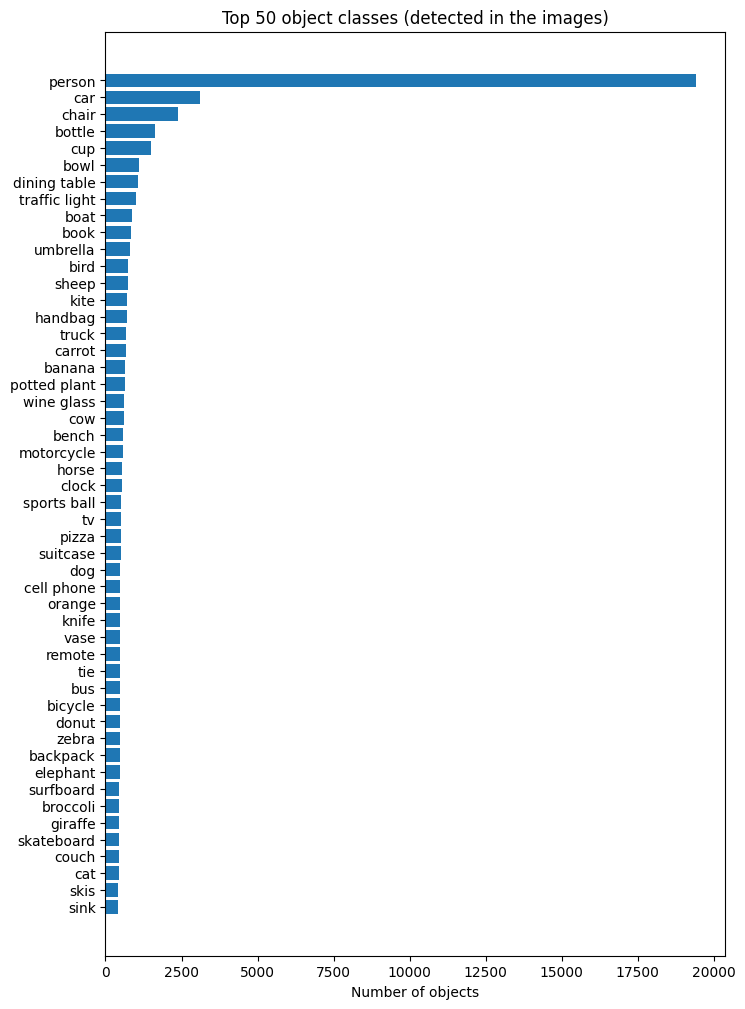

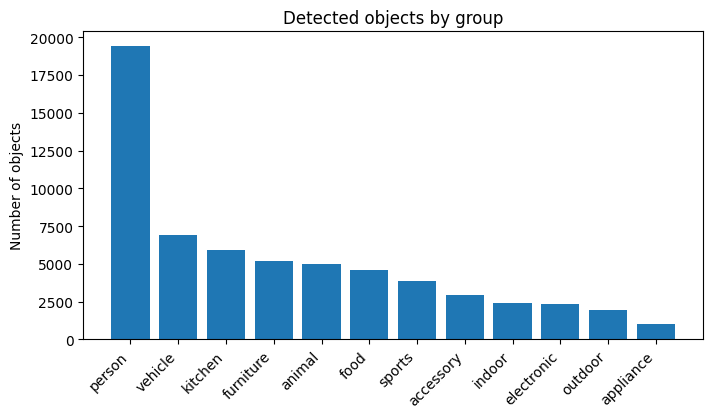

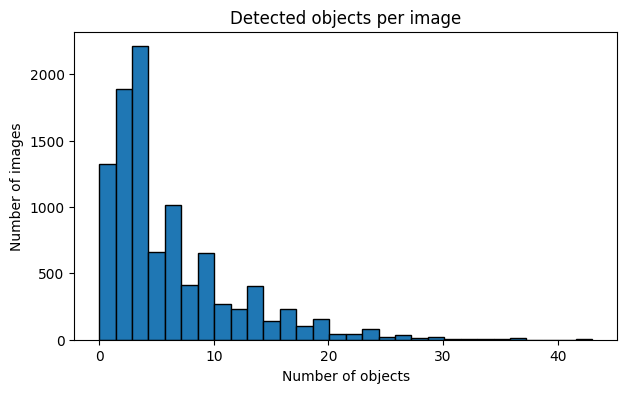

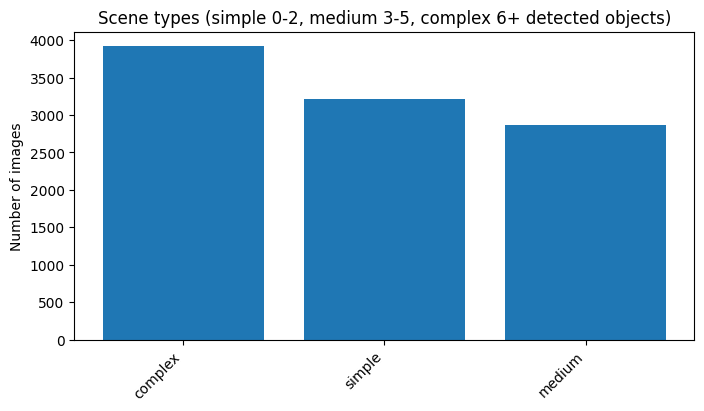

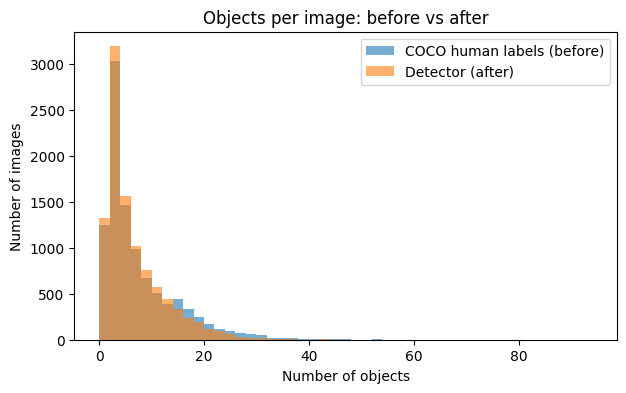

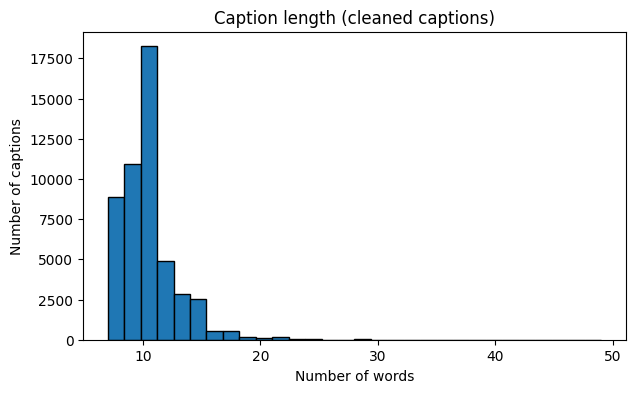

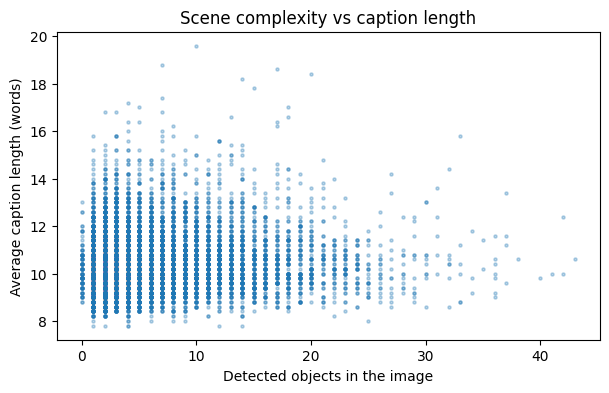

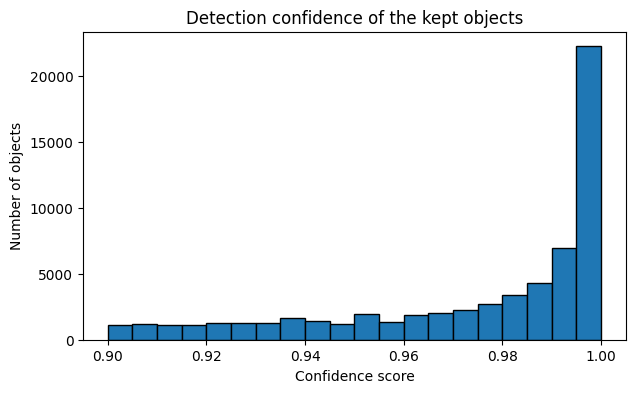

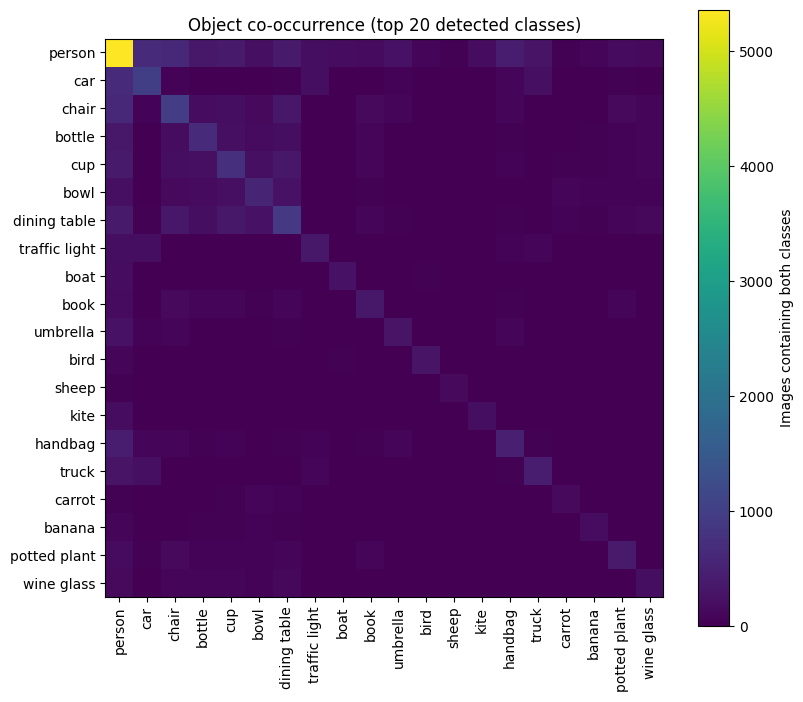

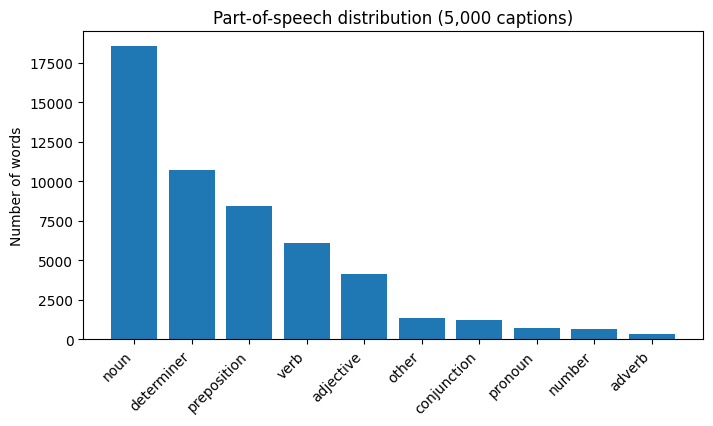

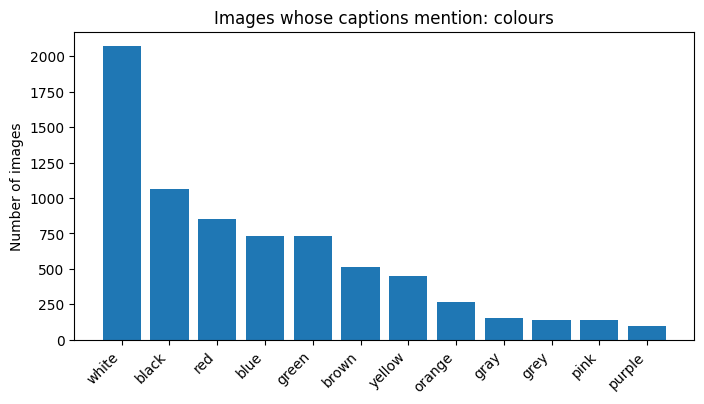

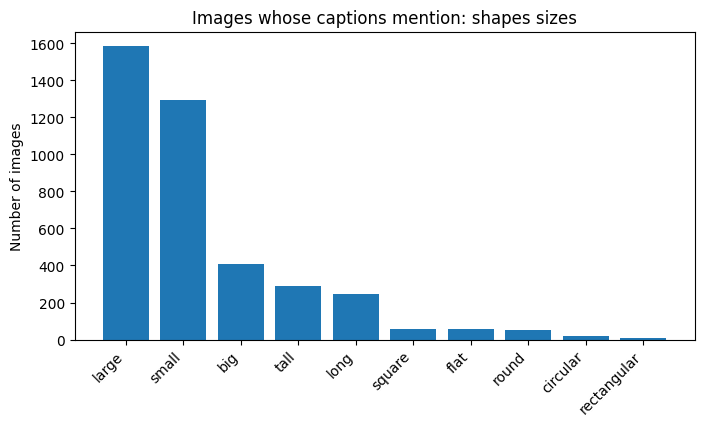

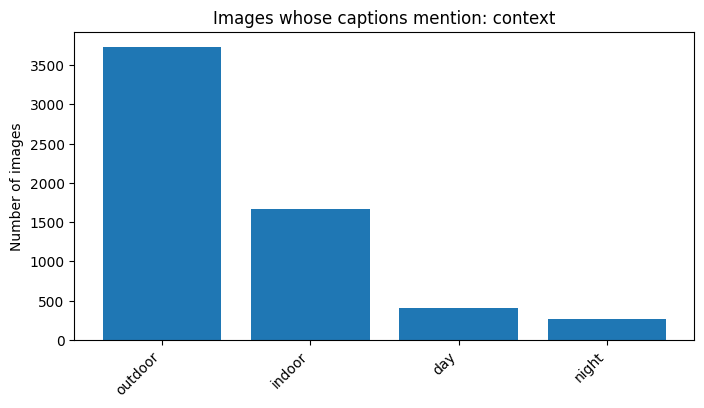

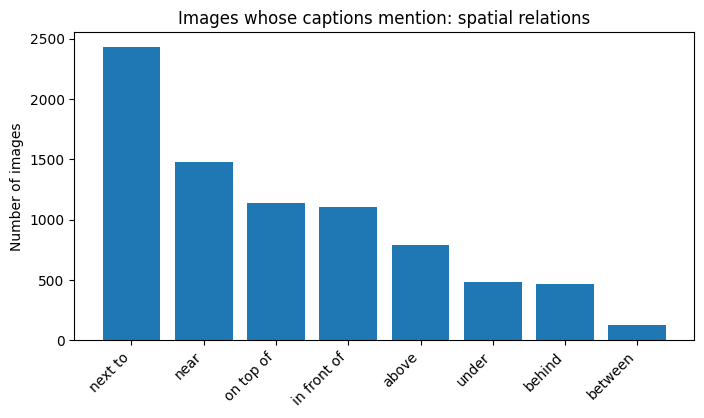

In [ ]:
# 2.6) CHANGED: exploration AFTER preprocessing. The statistics now start from the objects DETECTED in the images.
require('objects', 'kb_ids', 'captions', 'diversity', 'pos_counts', 'detected', 'raw_vocabulary', 'coco_per_image')

class_counts, group_counts = Counter(), Counter()
for names in objects.values():
    for name in names:
        class_counts[name] += 1
        group_counts[group_of.get(name, 'other')] += 1

objects_per_image = [len(objects[i]) for i in kb_ids]                                      # detected objects per image
scene_counts = Counter(scene_type(n) for n in objects_per_image)
clean_lengths = [len(clean_text(c).split()) for i in kb_ids for c in captions[i]]          # words per cleaned caption
average_caption_length = [np.mean([len(clean_text(c).split()) for c in captions[i]]) for i in kb_ids]
clean_vocabulary = {w for i in kb_ids for c in captions[i] for w in clean_text(c).split()}
confidences = [d['score'] for i in kb_ids for d in detected[i]]

after = {'average_objects_per_image': float(np.mean(objects_per_image)), 'images_without_objects': objects_per_image.count(0),
         'scene_types': dict(scene_counts), 'different_object_categories': len(class_counts),
         'average_detection_confidence': float(np.mean(confidences)),
         'average_caption_length_clean': float(np.mean(clean_lengths)), 'vocabulary_clean': len(clean_vocabulary),
         'image_modes': 'all RGB (conversion in the pipeline)', 'images_with_exif_rotation': 'corrected (0 left)'}

print(f'{"":<28}{"BEFORE":>14}{"AFTER":>14}')
print(f'{"Objects per image":<28}{np.mean(coco_per_image):>14.2f}{np.mean(objects_per_image):>14.2f}   (human COCO labels -> detector)')
print(f'{"Images without objects":<28}{coco_per_image.count(0):>14}{objects_per_image.count(0):>14}')
print(f'{"Avg caption length (words)":<28}{before["average_caption_length_raw"]:>14.2f}{np.mean(clean_lengths):>14.2f}')
print(f'{"Vocabulary size":<28}{len(raw_vocabulary):>14}{len(clean_vocabulary):>14}   (raw -> lowercase, no punctuation)')
print('Scene types (detector)      :', dict(scene_counts))
print('Different object categories :', len(class_counts), '| average detection confidence:', round(after['average_detection_confidence'], 3))

# 1) Distribution of object classes: the 50 most frequent (detected)
top_classes_plot(class_counts, 'Top 50 object classes (detected in the images)', 'after_top_50_classes.png')
# 2) The same, grouped (person, animal, vehicle, ...)
bar_plot(group_counts, 'Detected objects by group', 'Number of objects', 'after_groups.png')
# 3) Scene complexity = number of detected objects per image
hist_plot(objects_per_image, 'Detected objects per image', 'Number of objects', 'Number of images', 'after_objects_per_image.png')
bar_plot(scene_counts, 'Scene types (simple 0-2, medium 3-5, complex 6+ detected objects)', 'Number of images', 'after_scene_types.png')
# 4) Before vs after: human COCO labels against the detector
plt.figure(figsize=(7, 4))
bins = range(0, max(max(coco_per_image), max(objects_per_image)) + 2, 2)
plt.hist(coco_per_image, bins=bins, alpha=0.6, label='COCO human labels (before)')
plt.hist(objects_per_image, bins=bins, alpha=0.6, label='Detector (after)')
plt.legend()
show('Objects per image: before vs after', 'Number of objects', 'Number of images', 'before_vs_after_objects.png')
# 5) Caption length (cleaned captions)
hist_plot(clean_lengths, 'Caption length (cleaned captions)', 'Number of words', 'Number of captions', 'after_caption_length.png')
# 6) Do crowded scenes get longer captions?
plt.figure(figsize=(7, 4))
plt.scatter(objects_per_image, average_caption_length, s=5, alpha=0.3)
show('Scene complexity vs caption length', 'Detected objects in the image', 'Average caption length (words)', 'after_complexity_vs_length.png')
# 7) Detection confidence
hist_plot(confidences, 'Detection confidence of the kept objects', 'Confidence score', 'Number of objects', 'after_detection_confidence.png', bins=20)
# 8) Co-occurrence matrix: how many images contain both class i and class j (top 20 classes)
top20 = [name for name, n in class_counts.most_common(20)]
position = {name: k for k, name in enumerate(top20)}
matrix = np.zeros((len(top20), len(top20)), dtype=int)
for names in objects.values():
    present = [position[n] for n in set(names) if n in position]
    for a in present:
        for b in present:
            matrix[a, b] += 1
plt.figure(figsize=(9, 8))
plt.imshow(matrix)
plt.colorbar(label='Images containing both classes')
plt.xticks(range(len(top20)), top20, rotation=90)
plt.yticks(range(len(top20)), top20)
show('Object co-occurrence (top 20 detected classes)', '', '', 'after_cooccurrence.png')
# 9) Part-of-speech distribution
bar_plot(pos_counts, 'Part-of-speech distribution (5,000 captions)', 'Number of words', 'after_pos_distribution.png')
# 10) Diversity: colours, shapes, context, spatial relations (from the human captions)
for kind, counts in diversity.items():
    bar_plot(counts, f'Images whose captions mention: {kind.replace("_", " ")}', 'Number of images', f'after_diversity_{kind}.png')

In [ ]:
# 2.7) CHANGED: save the metadata (linked to the image ids) and all the numbers
require('objects', 'attributes', 'diversity', 'pos_counts', 'detected', 'before', 'after')

# one record per KB image. vector_row = row of this image in the image embeddings (Part 3)
records = [{'image_id': i, 'vector_row': row, 'captions': captions[i],
            'objects': objects[i], 'object_counts': dict(Counter(objects[i])),
            'detections': detected[i],                                  # label + confidence score + box, extracted from the image
            'coco_objects': coco_objects[i],                            # human annotation, confidence 1 (reference)
            'scene_type': scene_type(len(objects[i])), **attributes[i]}  # attributes come from human captions, confidence 1
           for row, i in enumerate(kb_ids)]
save_json(records, f'{BASE}/metadata/kb_records.json')
save_json({str(i): objects[i] for i in kb_ids}, f'{BASE}/metadata/objects.json')

# QUERY side (validation + test): objects detected in the image only. This is what the retrieval pipelines may use.
save_json({'validation': {str(i): detected[i] for i in validation_ids}, 'test_1000': {str(i): detected[i] for i in test1000_ids}},
          f'{BASE}/metadata/query_objects.json')
# EVALUATION ONLY (hallucination rate): human COCO objects of validation + test. Never use them for retrieval.
save_json({'validation': {str(i): coco_objects[i] for i in validation_ids}, 'test_1000': {str(i): coco_objects[i] for i in test1000_ids}},
          f'{BASE}/metadata/eval_objects.json')

save_json({'before_preprocessing': before,
           'after_preprocessing': after,
           'top_50_classes_detected': class_counts.most_common(50),
           'groups_detected': dict(group_counts),
           'pos': dict(pos_counts),
           'diversity': {kind: dict(c) for kind, c in diversity.items()},
           'detector_threshold': DETECTION_THRESHOLD}, f'{BASE}/metadata/statistics.json')
print('Saved:', len(records), 'KB records. Part 2 done.')

Saved: 10000 KB records. Part 2 done.


## Part 3: Embeddings, FAISS index, documentation

In [ ]:
# 3.1) Load CLIP and define the embedding functions
!pip install -q faiss-cpu

import faiss
import torch
import transformers
from torch.utils.data import Dataset, DataLoader
from transformers import CLIPModel, CLIPProcessor

splits, captions = load_splits()
kb_ids, validation_ids = splits['train_kb'], splits['validation']
test_ids, test1000_ids = splits['test'], splits['test_1000']

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using:', device)
if device == 'cpu':
    print('WARNING: no GPU. This will take very long. Runtime > Change runtime type > T4 GPU (then run Setup again).')
MODEL = 'openai/clip-vit-base-patch32'
IMAGE_BATCH, TEXT_BATCH = 64, 256
model = CLIPModel.from_pretrained(MODEL).to(device).eval()
processor = CLIPProcessor.from_pretrained(MODEL)
EMBED_DIM = model.config.projection_dim                        # 512 for this model


def to_unit_vectors(features):
    """Make every vector have length 1."""
    if not torch.is_tensor(features):                          # some library versions wrap the result
        features = features.pooler_output
    features = features.cpu().numpy()
    return (features / np.linalg.norm(features, axis=1, keepdims=True)).astype('float32')


class ImageFiles(Dataset):
    """Loads the images in the background while the GPU works."""
    def __init__(self, paths):
        self.paths = paths

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, k):
        # fix the rotation (EXIF), then 3 colour channels (RGB)
        return ImageOps.exif_transpose(Image.open(self.paths[k])).convert('RGB')


def collate(images):
    return processor(images=images, return_tensors='pt')       # the processor resizes + normalises for CLIP


def embed_images(ids, set_name):
    """Images -> vectors. Row k of the result = image ids[k]."""
    paths = [f'{BASE}/{FOLDER[set_name]}/{i:012d}.jpg' for i in ids]
    loader = DataLoader(ImageFiles(paths), batch_size=IMAGE_BATCH, num_workers=2, collate_fn=collate)   # no shuffle: order kept
    vectors = []
    for inputs in tqdm(loader):
        inputs = inputs.to(device)
        with torch.no_grad():
            vectors.append(to_unit_vectors(model.get_image_features(**inputs)))
    return np.concatenate(vectors)


def embed_texts(texts):
    """Captions -> vectors."""
    vectors = []
    for start in tqdm(range(0, len(texts), TEXT_BATCH)):
        inputs = processor(text=texts[start:start + TEXT_BATCH], padding=True, truncation=True,
                           return_tensors='pt').to(device)
        with torch.no_grad():
            vectors.append(to_unit_vectors(model.get_text_features(**inputs)))
    return np.concatenate(vectors)

Using: cuda


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

... (3 outputs left out)

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

In [ ]:
# 3.2) CHANGED: compute the vectors (or load them from Drive), check them, save them. Now also for the 1,000 test images.
require('model', 'processor', 'embed_images', 'embed_texts', 'kb_ids', 'test1000_ids')


def check_vectors(name, vectors, expected_rows):
    """Quality control: right shape, no NaN (missing numbers), every length = 1."""
    assert vectors.shape == (expected_rows, EMBED_DIM), f'{name}: wrong shape {vectors.shape}'
    assert not np.isnan(vectors).any(), f'{name}: contains NaN'
    assert np.allclose(np.linalg.norm(vectors, axis=1), 1, atol=1e-3), f'{name}: length is not 1'


def cached_vectors(name, expected_rows, compute):
    """Load the vectors from Drive if they exist, otherwise compute, check and save them."""
    path = f'{BASE}/embeddings/{name}.npy'
    if os.path.exists(path):
        vectors = np.load(path)
        print(f'{name}: loaded from Drive')
    else:
        vectors = compute()
        check_vectors(name, vectors, expected_rows)            # a bad result is never saved
        np.save(path, vectors)
        print(f'{name}: computed and saved')
    check_vectors(name, vectors, expected_rows)
    return vectors


caption_rows = [{'image_id': i, 'caption_raw': c, 'caption_clean': clean_text(c)}
                for i in kb_ids for c in captions[i]]
assert all(row['caption_raw'] == c for row, c in zip(caption_rows, [c for i in kb_ids for c in captions[i]])), 'a raw caption was changed'
assert len(set(kb_ids)) == len(kb_ids), 'duplicate ids in the KB'
assert test1000_ids[:TEST_SIZE] == test_ids, 'the 100 test images must be the first 100 of the 1,000'

kb_image_vectors = cached_vectors('kb_image_vectors', KB_SIZE, lambda: embed_images(kb_ids, 'train_kb'))
validation_image_vectors = cached_vectors('validation_image_vectors', VALIDATION_SIZE, lambda: embed_images(validation_ids, 'validation'))
test_image_vectors = cached_vectors('test_image_vectors', TEST_SIZE, lambda: embed_images(test_ids, 'test'))                 # test set A (100)
test1000_image_vectors = cached_vectors('test1000_image_vectors', TEST_1000_SIZE, lambda: embed_images(test1000_ids, 'test_1000'))   # test set B (1,000)
caption_vectors = cached_vectors('kb_caption_vectors', KB_SIZE * 5,
                                 lambda: embed_texts([row['caption_clean'] for row in caption_rows]))

# the 100 images are inside the 1,000: their vectors must be (almost) the same in both files
same = np.allclose(test1000_image_vectors[:TEST_SIZE], test_image_vectors, atol=1e-3)
print('Test 100 vectors identical inside the test 1,000 vectors:', 'OK' if same else 'WARNING: different (recompute one of the two files)')

# the ids files
np.save(f'{BASE}/embeddings/kb_image_ids.npy', np.array(kb_ids))
np.save(f'{BASE}/embeddings/validation_image_ids.npy', np.array(validation_ids))
np.save(f'{BASE}/embeddings/test_image_ids.npy', np.array(test_ids))
np.save(f'{BASE}/embeddings/test1000_image_ids.npy', np.array(test1000_ids))
save_json(caption_rows, f'{BASE}/metadata/kb_caption_rows.json')

print('KB images   :', kb_image_vectors.shape)
print('KB captions :', caption_vectors.shape)
print('Validation  :', validation_image_vectors.shape, '| Test 100:', test_image_vectors.shape, '| Test 1,000:', test1000_image_vectors.shape)
print('All embedding checks passed')

kb_image_vectors: loaded from Drive
validation_image_vectors: loaded from Drive
test_image_vectors: loaded from Drive


100%|██████████| 16/16 [00:19<00:00,  1.25s/it]


test1000_image_vectors: computed and saved
kb_caption_vectors: loaded from Drive
Test 100 vectors identical inside the test 1,000 vectors: OK
KB images   : (10000, 512)
KB captions : (50000, 512)
Validation  : (100, 512) | Test 100: (100, 512) | Test 1,000: (1000, 512)
All embedding checks passed


{'type': 'IndexFlatIP (flat, exact search)', 'similarity': 'cosine (inner product, vectors of length 1)', 'vectors': 10000, 'dimension': 512, 'size_MB': 20.48, 'indexing_seconds': 0.065}
{'type': 'IndexFlatIP (flat, exact search)', 'similarity': 'cosine (inner product, vectors of length 1)', 'vectors': 50000, 'dimension': 512, 'size_MB': 102.4, 'indexing_seconds': 0.115}
validation: 100 queries, top-10 image retrieval, no query image retrieved (OK)
test 100  : 100 queries, top-10 image retrieval, no query image retrieved (OK)
test 1,000: 1000 queries, top-10 image retrieval, no query image retrieved (OK)

Real captions of the test image: ['A man riding a kiteboard over the ocean under a gray sky.', 'A kite surfer gets high in the air while his kite is out of the picture frame.'] ...
Retrieved KB captions:
 - A man kiteboarding on top of the ocean.
 - A man kiteboarding over the ocean next to shore.
 - A parasailer holding on to the sail and waiting to land.
 - A person kiteboarding ove

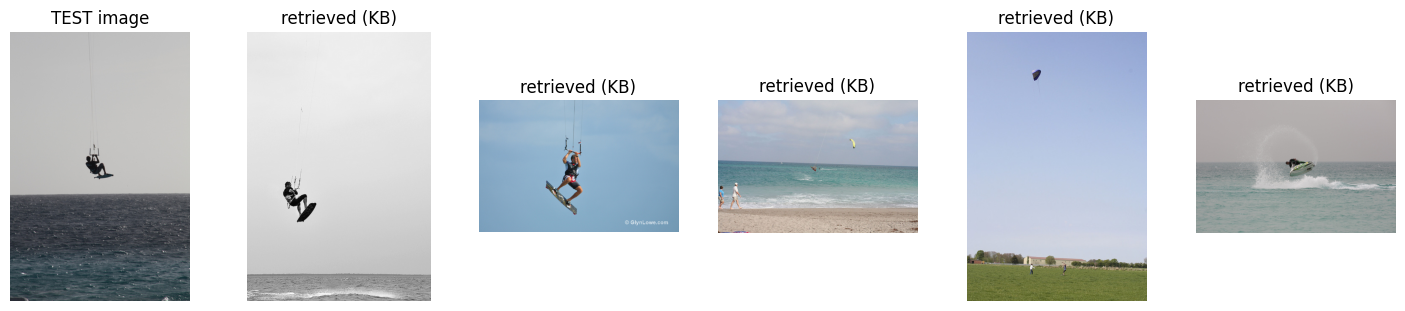

In [ ]:
# 3.3) FAISS index (the vector database). Flat = exact search, inner product on unit vectors = cosine similarity.
require('kb_image_vectors', 'caption_vectors', 'caption_rows', 'test_image_vectors', 'test1000_image_vectors')


def build_index(vectors, name):
    start = time.time()
    index = faiss.IndexFlatIP(vectors.shape[1])
    index.add(vectors)
    seconds = time.time() - start
    path = f'{BASE}/index/{name}.faiss'
    faiss.write_index(index, path)
    info = {'type': 'IndexFlatIP (flat, exact search)', 'similarity': 'cosine (inner product, vectors of length 1)',
            'vectors': index.ntotal, 'dimension': vectors.shape[1],
            'size_MB': round(os.path.getsize(path) / 1e6, 2), 'indexing_seconds': round(seconds, 3)}
    return index, info


image_index, image_index_info = build_index(kb_image_vectors, 'kb_images')
caption_index, caption_index_info = build_index(caption_vectors, 'kb_captions')
print(image_index_info)
print(caption_index_info)

# Leakage check on ALL query images: nothing retrieved from the KB may be a validation or test image
for name, vectors, ids in [('validation', validation_image_vectors, validation_ids), ('test 100', test_image_vectors, test_ids),
                           ('test 1,000', test1000_image_vectors, test1000_ids)]:
    retrieved = {kb_ids[k] for row in image_index.search(vectors, 10)[1] for k in row}
    assert not retrieved & set(ids), f'{name}: a query image was retrieved for itself'
    print(f'{name:<10}: {len(ids)} queries, top-10 image retrieval, no query image retrieved (OK)')

# Does retrieval work? One TEST image -> its 5 most similar KB captions and KB images
query = test_image_vectors[:1]
caption_rows_found = caption_index.search(query, 5)[1][0]
retrieved_images = [kb_ids[k] for k in image_index.search(query, 5)[1][0]]

print('\nReal captions of the test image:', captions[test_ids[0]][:2], '...')
print('Retrieved KB captions:')
for k in caption_rows_found:
    print(' -', caption_rows[k]['caption_raw'])

fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))
axes[0].imshow(Image.open(f'{BASE}/{FOLDER["test"]}/{test_ids[0]:012d}.jpg'))
axes[0].set_title('TEST image')
for ax, i in zip(axes[1:], retrieved_images):
    ax.imshow(Image.open(f'{BASE}/{FOLDER["train_kb"]}/{i:012d}.jpg'))
    ax.set_title('retrieved (KB)')
for ax in axes:
    ax.axis('off')
plt.show()

In [ ]:
# 3.4) CHANGED: Documentation of Phase 1 (everything the guide asks to record)
require('image_index_info', 'caption_index_info', 'MODEL', 'DETECTION_THRESHOLD')
detector_config = load_json(f'{BASE}/metadata/detector_config.json')
documentation = {
    'splits': {'train_kb': {'source': 'COCO train2017', 'size': len(kb_ids)},
               'validation': {'source': 'COCO train2017, different images from the KB', 'size': len(validation_ids)},
               'test_100': {'source': 'COCO val2017, stratified', 'size': len(test_ids), 'per_scene_type': TEST_PER_SCENE,
                            'note': 'first version of the test set, kept for comparison; it is INSIDE test_1000'},
               'test_1000': {'source': 'COCO val2017, stratified (includes test_100)', 'size': len(test1000_ids),
                             'per_scene_type': TEST_PER_SCENE_1000},
               'scene_types': 'simple = 0-2 objects, medium = 3-5, complex = 6 or more (counted with the COCO annotations for the test stratification)',
               'random_seed': SEED, 'split_ids_file': 'splits.json'},
    'audit': {'removed_images': load_json(f'{BASE}/metadata/cleaning_report.json'),
              'leakage_audit': load_json(f'{BASE}/metadata/leakage_audit.json')},
    'preprocessing': {
        'images': 'EXIF rotation fixed, converted to RGB, resized + normalised by the CLIP processor',
        'captions': 'caption_raw = original (evaluation), caption_clean = lowercase + no punctuation (retrieval only)',
        'metadata': {
            'objects': f'extracted FROM THE IMAGES by {DETECTOR} (labels, scores, boxes), threshold {DETECTION_THRESHOLD} '
                       f'chosen on the validation images, stored from score {DETECTOR_MIN_SCORE}',
            'object_confidence': 'the detector score is the confidence of each object',
            'human_data_confidence': f'{ANNOTATION_CONFIDENCE} for COCO captions, COCO annotations (coco_objects) and the attributes taken '
                                     'from the captions, because people wrote them',
            'attributes': 'colours, shapes, context and spatial relations are taken from caption words (COCO does not provide them); KB images only',
            'query_side': 'query_objects.json = detected objects of validation/test images (allowed for retrieval)',
            'evaluation_only': 'eval_objects.json = human COCO objects of validation/test images, never used for retrieval'},
        'exploration': 'before preprocessing (raw images, raw captions, COCO labels) and after (detected objects, cleaned captions); see statistics.json and plots/'},
    'detector': detector_config,
    'embeddings': {'model': MODEL, 'dimension': EMBED_DIM, 'image_batch_size': IMAGE_BATCH, 'text_batch_size': TEXT_BATCH,
                   'normalisation': 'every vector has length 1', 'format': '.npy'},
    'indexes': {'images': image_index_info, 'captions': caption_index_info},
    'versions': {'numpy': np.__version__, 'torch': torch.__version__, 'transformers': transformers.__version__,
                 'faiss': faiss.__version__, 'device': device},
}
save_json(documentation, f'{BASE}/metadata/phase1_documentation.json')
print(json.dumps(documentation, indent=2)[:2500])

{
  "splits": {
    "train_kb": {
      "source": "COCO train2017",
      "size": 10000
    },
    "validation": {
      "source": "COCO train2017, different images from the KB",
      "size": 100
    },
    "test_100": {
      "source": "COCO val2017, stratified",
      "size": 100,
      "per_scene_type": {
        "simple": 34,
        "medium": 33,
        "complex": 33
      },
      "note": "first version of the test set, kept for comparison; it is INSIDE test_1000"
    },
    "test_1000": {
      "source": "COCO val2017, stratified (includes test_100)",
      "size": 1000,
      "per_scene_type": {
        "simple": 334,
        "medium": 333,
        "complex": 333
      }
    },
    "scene_types": "simple = 0-2 objects, medium = 3-5, complex = 6 or more (counted with the COCO annotations for the test stratification)",
    "random_seed": 42,
    "split_ids_file": "splits.json"
  },
  "audit": {
    "removed_images": {
      "train_kb": {
        "missing": 0,
        "corrupted